
# 02 — Baseline, contact point e primo fit Hertz-like

Questo notebook parte dagli output già generati dal reader:

```text
afm_output/
├── csv_curves/
├── summary_segment0_with_qc.csv
└── plots_overview/
```

Obiettivo: prendere le curve già convertite in CSV, stimare baseline e contact point, costruire una indentazione relativa e fare un primo fit meccanico:

\[
F(\delta) = A\,\delta^{3/2}
\]

Per ora `A` è un **parametro elastico efficace**, non ancora il modulo di Young assoluto. Per convertirlo in \(E\) servono geometria della punta, raggio e coefficiente di Poisson.


In [7]:

from pathlib import Path
import re
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.optimize import curve_fit
from scipy.signal import savgol_filter

warnings.filterwarnings("ignore")

PROJECT_DIR = Path.cwd()
OUTPUT_DIR = PROJECT_DIR / "afm_output"
CSV_DIR = OUTPUT_DIR / "csv_curves"
SUMMARY_PATH = OUTPUT_DIR / "summary_segment0_with_qc.csv"

FIT_OUTPUT_DIR = OUTPUT_DIR / "fit_hertz_like"
FIT_PLOTS_DIR = FIT_OUTPUT_DIR / "plots"
FIT_TABLE_PATH = FIT_OUTPUT_DIR / "fit_results_segment0.csv"

FIT_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FIT_PLOTS_DIR.mkdir(parents=True, exist_ok=True)

print("Working directory:", PROJECT_DIR)
print("CSV_DIR exists:", CSV_DIR.exists(), CSV_DIR)
print("SUMMARY exists:", SUMMARY_PATH.exists(), SUMMARY_PATH)


Working directory: /Users/gmoretti/Work/AFM/Code_General
CSV_DIR exists: True /Users/gmoretti/Work/AFM/Code_General/afm_output/csv_curves
SUMMARY exists: True /Users/gmoretti/Work/AFM/Code_General/afm_output/summary_segment0_with_qc.csv



## 1. Caricamento del summary

Il summary contiene una riga per curva. Lo useremo per sapere quali curve esistono, a quale gruppo appartengono e quali erano state eventualmente flaggate nel controllo qualità preliminare.


In [8]:

summary = pd.read_csv(SUMMARY_PATH)
print("Numero righe summary:", len(summary))
display(summary.head())

print("\nColonne disponibili:")
print(list(summary.columns))


Numero righe summary: 257


,status,file,file_name,group,segment_id,segment_style,segment_name,n_points,z_min_um,z_max_um,...,cantilever_id,tip_radius,tip_half_angle,time_stamp,force_corr_max_nN_robust_z,baseline_noise_pN_robust_z,z_range_um_robust_z,n_points_robust_z,qc_score,qc_flag_simple
0,ok,Curve di forza belle/Petri20k_MCF7R_t48h_cito_...,cito-0000.jpk-force,Petri20k_MCF7R_t48h_cito_20260225,0,extend,extend-spm,6000,-15.409008,-9.411679,...,2300FE,NaN,NaN,2026-02-25 09\:09\:43.503 +0100,0.086722,1.260798,1.417023,NaN,1.417023,False
1,ok,Curve di forza belle/Petri20k_MCF7R_t48h_cito_...,cito-0005.jpk-force,Petri20k_MCF7R_t48h_cito_20260225,0,extend,extend-spm,4700,-15.592912,-10.896858,...,2300FE,NaN,NaN,2026-02-25 09\:11\:47.886 +0100,1.022848,0.564639,-545.355224,NaN,545.355224,True
2,ok,Curve di forza belle/Petri20k_MCF7R_t48h_cito_...,cito-0006.jpk-force,Petri20k_MCF7R_t48h_cito_20260225,0,extend,extend-spm,5413,-15.767386,-10.357957,...,2300FE,NaN,NaN,2026-02-25 09\:11\:49.808 +0100,-0.283640,4.543361,-245.608188,NaN,245.608188,True
3,ok,Curve di forza belle/Petri20k_MCF7R_t48h_cito_...,cito-0007.jpk-force,Petri20k_MCF7R_t48h_cito_20260225,0,extend,extend-spm,6000,-15.621139,-9.624797,...,2300FE,NaN,NaN,2026-02-25 09\:11\:51.934 +0100,-0.442651,0.387903,1.002005,NaN,1.002005,False
4,ok,Curve di forza belle/Petri20k_MCF7R_t48h_cito_...,cito-0008.jpk-force,Petri20k_MCF7R_t48h_cito_20260225,0,extend,extend-spm,6000,-15.645828,-9.651365,...,2300FE,NaN,NaN,2026-02-25 09\:11\:54.151 +0100,1.600985,0.946572,0.212477,NaN,1.600985,False



Colonne disponibili:
['status', 'file', 'file_name', 'group', 'segment_id', 'segment_style', 'segment_name', 'n_points', 'z_min_um', 'z_max_um', 'z_range_um', 'force_min_nN', 'force_max_nN', 'force_corr_max_nN', 'force_corr_min_nN', 'baseline_nN', 'baseline_noise_pN', 'spring_N_per_m', 'sensitivity_m_per_V', 'cantilever_name', 'cantilever_id', 'tip_radius', 'tip_half_angle', 'time_stamp', 'force_corr_max_nN_robust_z', 'baseline_noise_pN_robust_z', 'z_range_um_robust_z', 'n_points_robust_z', 'qc_score', 'qc_flag_simple']



## 2. Trova i CSV delle curve

Il notebook cerca automaticamente i CSV del segmento 0, cioè quello che stiamo trattando come approach/extend.

Se il nome dei file esportati è diverso, questa cella stampa esempi così possiamo adattare il pattern.


In [9]:

all_csv = sorted(CSV_DIR.rglob("*.csv"))

print("CSV trovati:", len(all_csv))
print("Primi 20 CSV:")
for p in all_csv[:20]:
    print(p.relative_to(CSV_DIR))

seg0_csv = [
    p for p in all_csv
    if (
        "segment0" in p.name.lower()
        or "segment_0" in p.name.lower()
        or "seg0" in p.name.lower()
        or "seg_0" in p.name.lower()
    )
]

print("\nCSV segmento 0 selezionati:", len(seg0_csv))

if len(seg0_csv) == 0:
    raise RuntimeError(
        "Non ho trovato CSV del segmento 0. "
        "Controlla i nomi dei file dentro le sottocartelle di csv_curves."
    )


CSV trovati: 514
Primi 20 CSV:
Petri20k_MCF7R_t48h_cito_20260225/cito-0000_segment0.csv
Petri20k_MCF7R_t48h_cito_20260225/cito-0000_segment1.csv
Petri20k_MCF7R_t48h_cito_20260225/cito-0005_segment0.csv
Petri20k_MCF7R_t48h_cito_20260225/cito-0005_segment1.csv
Petri20k_MCF7R_t48h_cito_20260225/cito-0006_segment0.csv
Petri20k_MCF7R_t48h_cito_20260225/cito-0006_segment1.csv
Petri20k_MCF7R_t48h_cito_20260225/cito-0007_segment0.csv
Petri20k_MCF7R_t48h_cito_20260225/cito-0007_segment1.csv
Petri20k_MCF7R_t48h_cito_20260225/cito-0008_segment0.csv
Petri20k_MCF7R_t48h_cito_20260225/cito-0008_segment1.csv
Petri20k_MCF7R_t48h_cito_20260225/cito-0009_segment0.csv
Petri20k_MCF7R_t48h_cito_20260225/cito-0009_segment1.csv
Petri20k_MCF7R_t48h_cito_20260225/cito-0011_segment0.csv
Petri20k_MCF7R_t48h_cito_20260225/cito-0011_segment1.csv
Petri20k_MCF7R_t48h_cito_20260225/cito-0012_segment0.csv
Petri20k_MCF7R_t48h_cito_20260225/cito-0012_segment1.csv
Petri20k_MCF7R_t48h_cito_20260225/cito-0013_segment0.csv



## 3. Funzioni: pulizia, contact point e fit

La logica è volutamente semplice e robusta:

1. prende `z_tip_um` e `force_nN`;
2. sottrae la baseline stimata sulla parte iniziale della curva;
3. liscia leggermente la forza per stimare il punto di contatto;
4. trova il primo punto in cui la forza supera una soglia basata sul rumore;
5. definisce l'indentazione relativa come distanza dal contact point;
6. fitta la regione post-contatto con \(F = A \delta^{3/2}\).

Questa è una prima versione. Non pretende ancora di sostituire il workflow manuale.


In [10]:

def sanitize_name(s):
    return re.sub(r"[^A-Za-z0-9_.-]+", "_", str(s))


def hertz_like(delta_um, A):
    """F [nN] = A * delta_um^(3/2)."""
    delta_um = np.asarray(delta_um)
    return A * np.power(np.clip(delta_um, 0, None), 1.5)


def get_columns(df):
    """Trova colonne principali anche se il reader ha nomi leggermente diversi."""
    z_candidates = ["z_tip_um", "verticalTipPosition_um", "z_um"]
    f_candidates = ["force_nN", "force_corr_nN", "Force_nN"]

    z_col = next((c for c in z_candidates if c in df.columns), None)
    f_col = next((c for c in f_candidates if c in df.columns), None)

    if z_col is None:
        z_like = [c for c in df.columns if ("z" in c.lower() or "position" in c.lower()) and "um" in c.lower()]
        z_col = z_like[0] if z_like else None

    if f_col is None:
        f_like = [c for c in df.columns if "force" in c.lower() and "nn" in c.lower()]
        f_col = f_like[0] if f_like else None

    if z_col is None or f_col is None:
        raise ValueError(f"Non trovo colonne z/force. Colonne disponibili: {list(df.columns)}")

    return z_col, f_col


def robust_baseline(force, frac=0.20):
    n = len(force)
    nbase = max(20, int(frac * n))
    base_region = force[:nbase]
    baseline = np.nanmedian(base_region)
    noise = 1.4826 * np.nanmedian(np.abs(base_region - baseline))
    if not np.isfinite(noise) or noise == 0:
        noise = np.nanstd(base_region)
    return baseline, noise, nbase


def estimate_contact_point(z_um, force_corr_nN, baseline_noise_nN, threshold_sigma=5.0, min_consecutive=20):
    """
    Stima semplice del contact point:
    primo punto in cui la forza smoothed supera threshold_sigma * baseline_noise
    per almeno min_consecutive punti consecutivi.
    """
    n = len(force_corr_nN)

    win = min(101, max(11, (n // 50) | 1))
    if win >= n:
        win = max(5, (n // 5) | 1)
    try:
        f_smooth = savgol_filter(force_corr_nN, window_length=win, polyorder=2)
    except Exception:
        f_smooth = force_corr_nN.copy()

    threshold = max(threshold_sigma * baseline_noise_nN, 0.02 * np.nanmax(force_corr_nN))
    above = f_smooth > threshold

    contact_idx = None
    for i in range(0, n - min_consecutive):
        if np.all(above[i:i + min_consecutive]):
            contact_idx = i
            break

    if contact_idx is None:
        grad = np.gradient(f_smooth, z_um)
        search_start = int(0.10 * n)
        search_end = int(0.90 * n)
        if search_end <= search_start:
            search_start, search_end = 0, n
        contact_idx = search_start + int(np.nanargmax(np.abs(grad[search_start:search_end])))

    return int(contact_idx), f_smooth, threshold


def choose_fit_region(delta_um, force_corr_nN, contact_idx, min_points=80, max_delta_quantile=0.85):
    """
    Prende punti post-contatto con forza positiva.
    Limita il fit alla parte non estrema per evitare saturazione/fondo curva.
    """
    d = delta_um[contact_idx:]
    f = force_corr_nN[contact_idx:]

    mask = np.isfinite(d) & np.isfinite(f) & (d > 0) & (f > 0)
    if np.sum(mask) < min_points:
        return None, None, None

    d2 = d[mask]
    f2 = f[mask]

    dmax = np.nanquantile(d2, max_delta_quantile)
    mask2 = d2 <= dmax

    dfit = d2[mask2]
    ffit = f2[mask2]

    if len(dfit) < min_points:
        dfit, ffit = d2, f2

    return dfit, ffit, mask


def fit_hertz_like_curve(csv_path, make_plot=True):
    df = pd.read_csv(csv_path)
    z_col, f_col = get_columns(df)

    z = df[z_col].to_numpy(dtype=float)
    f = df[f_col].to_numpy(dtype=float)

    good = np.isfinite(z) & np.isfinite(f)
    z = z[good]
    f = f[good]

    if len(z) < 200:
        raise ValueError("Troppi pochi punti utili.")

    if z[-1] < z[0]:
        z = z[::-1]
        f = f[::-1]

    baseline, noise, nbase = robust_baseline(f, frac=0.20)
    fcorr = f - baseline

    contact_idx, f_smooth, threshold = estimate_contact_point(z, fcorr, noise)
    z0 = z[contact_idx]

    delta = z - z0

    dfit, ffit, fit_mask = choose_fit_region(delta, fcorr, contact_idx)
    if dfit is None:
        raise ValueError("Fit region insufficiente.")

    p0 = [np.nanmax(ffit) / max(np.nanmax(dfit)**1.5, 1e-9)]
    popt, pcov = curve_fit(hertz_like, dfit, ffit, p0=p0, maxfev=20000)
    A = popt[0]
    A_err = float(np.sqrt(pcov[0, 0])) if pcov is not None and np.isfinite(pcov[0, 0]) else np.nan

    pred = hertz_like(dfit, A)
    resid = ffit - pred
    rss = float(np.nansum(resid**2))
    tss = float(np.nansum((ffit - np.nanmean(ffit))**2))
    r2 = 1.0 - rss / tss if tss > 0 else np.nan
    rmse = float(np.sqrt(np.nanmean(resid**2)))

    result = {
        "csv_file": csv_path.name,
        "csv_path": str(csv_path),
        "n_points": len(z),
        "z_min_um": float(np.nanmin(z)),
        "z_max_um": float(np.nanmax(z)),
        "baseline_nN": float(baseline),
        "baseline_noise_pN": float(noise * 1000.0),
        "contact_idx": int(contact_idx),
        "contact_z_um": float(z0),
        "threshold_nN": float(threshold),
        "n_fit_points": int(len(dfit)),
        "delta_fit_min_um": float(np.nanmin(dfit)),
        "delta_fit_max_um": float(np.nanmax(dfit)),
        "A_nN_per_um_3over2": float(A),
        "A_err_nN_per_um_3over2": float(A_err),
        "fit_rmse_nN": rmse,
        "fit_r2": float(r2),
        "fit_status": "ok",
    }

    if make_plot:
        fig, ax = plt.subplots(figsize=(7.5, 5))
        ax.plot(z, fcorr, lw=0.8, alpha=0.7, label="curve baseline-corrected")
        ax.plot(z, f_smooth, lw=1.0, alpha=0.9, label="smoothed")
        ax.axvline(z0, ls="--", lw=1.2, label="estimated contact")
        ax.axhline(threshold, ls=":", lw=1.0, label="threshold")

        zfit = z0 + dfit
        ax.scatter(zfit, ffit, s=4, alpha=0.35, label="fit points")

        dgrid = np.linspace(np.nanmin(dfit), np.nanmax(dfit), 300)
        ax.plot(z0 + dgrid, hertz_like(dgrid, A), lw=2, label=r"fit $A\delta^{3/2}$")

        ax.set_xlabel("Vertical tip position [µm]")
        ax.set_ylabel("Force - baseline [nN]")
        ax.set_title(csv_path.stem)
        ax.grid(alpha=0.3)
        ax.legend(fontsize=8)
        fig.tight_layout()

        out_png = FIT_PLOTS_DIR / f"{sanitize_name(csv_path.stem)}__fit.png"
        fig.savefig(out_png, dpi=160, bbox_inches="tight")
        plt.close(fig)
        result["fit_plot"] = str(out_png)

    return result


In [11]:
from pathlib import Path
import re

print("PROJECT_DIR =", Path.cwd())
print("OUTPUT_DIR exists =", OUTPUT_DIR.exists(), OUTPUT_DIR)
print("CSV_DIR exists =", CSV_DIR.exists(), CSV_DIR)

all_csv = sorted(CSV_DIR.glob("*.csv"))
print("Numero CSV trovati:", len(all_csv))

print("\nPrimi 30 file nella cartella csv_curves:")
for p in all_csv[:30]:
    print(p.name)

print("\nContenuto di afm_output:")
if OUTPUT_DIR.exists():
    for p in OUTPUT_DIR.iterdir():
        print("-", p.name, "DIR" if p.is_dir() else "FILE")

PROJECT_DIR = /Users/gmoretti/Work/AFM/Code_General
OUTPUT_DIR exists = True /Users/gmoretti/Work/AFM/Code_General/afm_output
CSV_DIR exists = True /Users/gmoretti/Work/AFM/Code_General/afm_output/csv_curves
Numero CSV trovati: 0

Primi 30 file nella cartella csv_curves:

Contenuto di afm_output:
- summary_segment0_with_qc.csv FILE
- csv_curves DIR
- plots_overview DIR
- plots_qc DIR
- fit_hertz_like DIR
- summary_segment0.csv FILE
- metadata DIR



## 4. Test su una curva singola

Prima di lanciare il fit su tutte le curve, guardiamo un singolo caso.


In [12]:

test_csv = seg0_csv[0]
print("Test CSV:", test_csv)

res = fit_hertz_like_curve(test_csv, make_plot=True)
res


Test CSV: /Users/gmoretti/Work/AFM/Code_General/afm_output/csv_curves/Petri20k_MCF7R_t48h_cito_20260225/cito-0000_segment0.csv


{'csv_file': 'cito-0000_segment0.csv',
 'csv_path': '/Users/gmoretti/Work/AFM/Code_General/afm_output/csv_curves/Petri20k_MCF7R_t48h_cito_20260225/cito-0000_segment0.csv',
 'n_points': 6000,
 'z_min_um': -15.409008483402433,
 'z_max_um': -9.411678547621705,
 'baseline_nN': 0.07432009280817514,
 'baseline_noise_pN': 25.90968727004963,
 'contact_idx': 0,
 'contact_z_um': -15.409008483402433,
 'threshold_nN': 0.12954843635024815,
 'n_fit_points': 889,
 'delta_fit_min_um': 0.0007876224117371322,
 'delta_fit_max_um': 2.2768117560190166,
 'A_nN_per_um_3over2': 0.005593636211587665,
 'A_err_nN_per_um_3over2': 0.0044205217520226344,
 'fit_rmse_nN': 0.18603338011027795,
 'fit_r2': -0.5219247209988418,
 'fit_status': 'ok',
 'fit_plot': '/Users/gmoretti/Work/AFM/Code_General/afm_output/fit_hertz_like/plots/cito-0000_segment0__fit.png'}

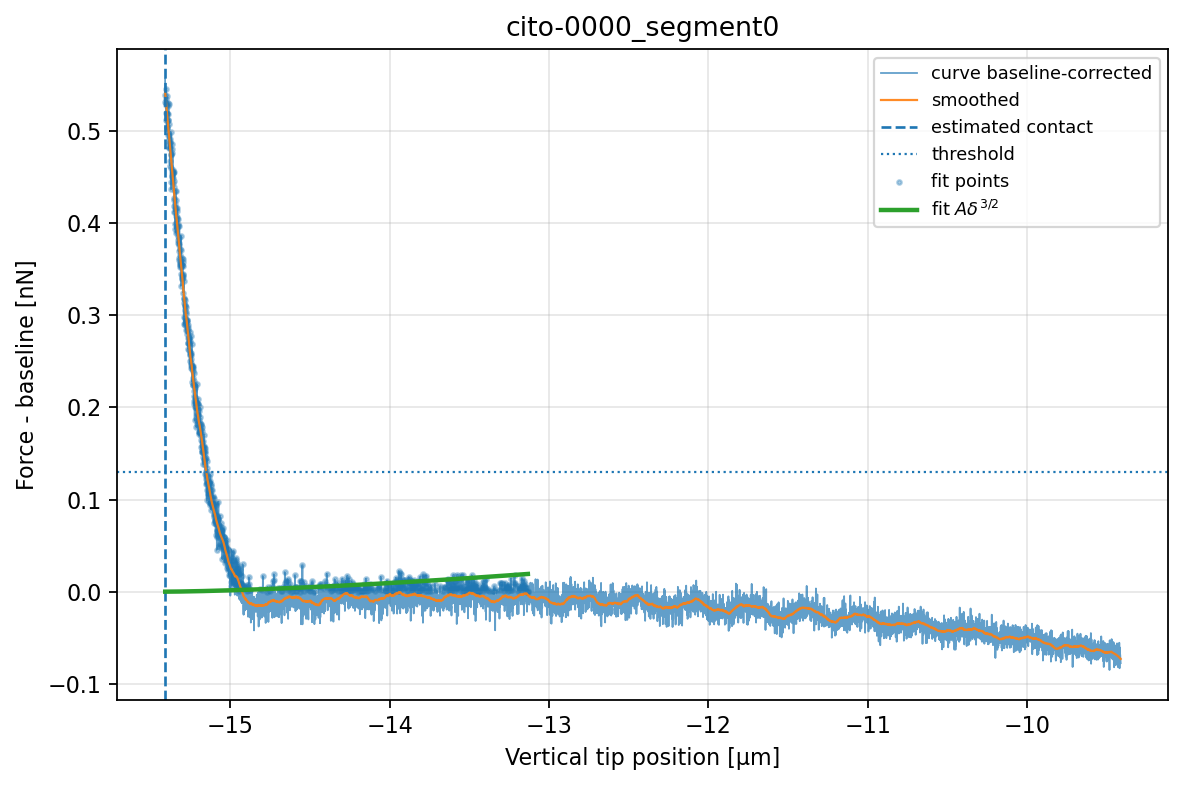

In [13]:

from IPython.display import Image, display

display(Image(filename=res["fit_plot"]))



## 5. Fit batch su tutte le curve segmento 0

Questa cella può richiedere un po' di tempo. Produce:

```text
afm_output/fit_hertz_like/fit_results_segment0.csv
afm_output/fit_hertz_like/plots/*.png
```


In [14]:

results = []
failures = []

for i, csv_path in enumerate(seg0_csv, start=1):
    try:
        r = fit_hertz_like_curve(csv_path, make_plot=True)
        results.append(r)
    except Exception as e:
        failures.append({"csv_file": csv_path.name, "csv_path": str(csv_path), "fit_status": "failed", "error": str(e)})

    if i % 25 == 0 or i == len(seg0_csv):
        print(f"Processed {i}/{len(seg0_csv)}")

fit_results = pd.DataFrame(results + failures)
fit_results.to_csv(FIT_TABLE_PATH, index=False)

print("Fit ok:", len(results))
print("Fit failed:", len(failures))
print("Saved:", FIT_TABLE_PATH)

display(fit_results.head())


Processed 25/257
Processed 50/257
Processed 75/257
Processed 100/257
Processed 125/257
Processed 150/257
Processed 175/257
Processed 200/257
Processed 225/257
Processed 250/257
Processed 257/257
Fit ok: 82
Fit failed: 175
Saved: /Users/gmoretti/Work/AFM/Code_General/afm_output/fit_hertz_like/fit_results_segment0.csv


,csv_file,csv_path,n_points,z_min_um,z_max_um,baseline_nN,baseline_noise_pN,contact_idx,contact_z_um,threshold_nN,n_fit_points,delta_fit_min_um,delta_fit_max_um,A_nN_per_um_3over2,A_err_nN_per_um_3over2,fit_rmse_nN,fit_r2,fit_status,fit_plot,error
0,cito-0000_segment0.csv,/Users/gmoretti/Work/AFM/Code_General/afm_outp...,6000.0,-15.409008,-9.411679,0.074320,25.909687,0.0,-15.409008,0.129548,889.0,0.000788,2.276812,0.005594,0.004421,0.186033,-0.521925,ok,/Users/gmoretti/Work/AFM/Code_General/afm_outp...,NaN
1,cito-0005_segment0.csv,/Users/gmoretti/Work/AFM/Code_General/afm_outp...,4700.0,-15.592912,-10.896858,0.122009,79.385963,0.0,-15.592912,0.396930,398.0,0.000855,0.393131,0.927548,0.123883,0.304275,-1.918422,ok,/Users/gmoretti/Work/AFM/Code_General/afm_outp...,NaN
2,cito-0007_segment0.csv,/Users/gmoretti/Work/AFM/Code_General/afm_outp...,6000.0,-15.621139,-9.624797,0.150196,53.647887,0.0,-15.621139,0.268239,516.0,0.000891,0.512228,0.632332,0.057046,0.237547,-2.705805,ok,/Users/gmoretti/Work/AFM/Code_General/afm_outp...,NaN
3,cito-0008_segment0.csv,/Users/gmoretti/Work/AFM/Code_General/afm_outp...,6000.0,-15.645828,-9.651365,0.137774,85.841233,0.0,-15.645828,0.429206,509.0,0.000900,0.503819,0.694617,0.074727,0.301123,-2.033334,ok,/Users/gmoretti/Work/AFM/Code_General/afm_outp...,NaN
4,cito-0009_segment0.csv,/Users/gmoretti/Work/AFM/Code_General/afm_outp...,6000.0,-15.591369,-9.596232,0.185584,70.584542,0.0,-15.591369,0.352923,509.0,0.000799,0.504117,0.544087,0.076297,0.307301,-1.505014,ok,/Users/gmoretti/Work/AFM/Code_General/afm_outp...,NaN



## 6. Recupera gruppo sperimentale dal nome/percorso

Se il CSV contiene già `meta_group`, usiamo quello. Altrimenti cerchiamo di ricostruirlo dal nome del file/percorso.


In [15]:

def infer_group_from_csv(csv_path):
    try:
        df0 = pd.read_csv(csv_path, nrows=1)
        if "meta_group" in df0.columns:
            return str(df0["meta_group"].iloc[0])
    except Exception:
        pass

    s = str(csv_path)
    known_groups = summary["group"].dropna().unique() if "group" in summary.columns else []
    for g in known_groups:
        if str(g) in s:
            return str(g)
    return "unknown"

fit_results["group"] = fit_results["csv_path"].apply(infer_group_from_csv)
fit_results.to_csv(FIT_TABLE_PATH, index=False)

display(fit_results[["csv_file", "group", "fit_status", "A_nN_per_um_3over2", "A_err_nN_per_um_3over2", "fit_r2", "fit_rmse_nN"]].head())


,csv_file,group,fit_status,A_nN_per_um_3over2,A_err_nN_per_um_3over2,fit_r2,fit_rmse_nN
0,cito-0000_segment0.csv,Petri20k_MCF7R_t48h_cito_20260225,ok,0.005594,0.004421,-0.521925,0.186033
1,cito-0005_segment0.csv,Petri20k_MCF7R_t48h_cito_20260225,ok,0.927548,0.123883,-1.918422,0.304275
2,cito-0007_segment0.csv,Petri20k_MCF7R_t48h_cito_20260225,ok,0.632332,0.057046,-2.705805,0.237547
3,cito-0008_segment0.csv,Petri20k_MCF7R_t48h_cito_20260225,ok,0.694617,0.074727,-2.033334,0.301123
4,cito-0009_segment0.csv,Petri20k_MCF7R_t48h_cito_20260225,ok,0.544087,0.076297,-1.505014,0.307301



## 7. Primo controllo dei risultati

Questi grafici non sono ancora conclusivi: servono a capire se il fit sta lavorando in modo ragionevole e se alcuni gruppi hanno distribuzioni molto diverse del parametro efficace \(A\).


Fit validi: 82


,A_nN_per_um_3over2,A_err_nN_per_um_3over2,fit_r2,fit_rmse_nN,baseline_noise_pN
count,82.000000,82.000000,82.000000,82.000000,82.000000
mean,0.335907,0.041431,-1.337137,0.211306,49.762687
std,0.305065,0.033974,0.827383,0.065601,21.283376
min,0.000926,0.000169,-3.103462,0.067370,13.661861
25%,0.001885,0.002152,-1.888123,0.174925,31.195722
50%,0.356987,0.054350,-1.498685,0.226468,49.085216
75%,0.558544,0.065437,-0.518337,0.258175,62.486638
max,1.290523,0.129374,-0.112989,0.320758,101.625896


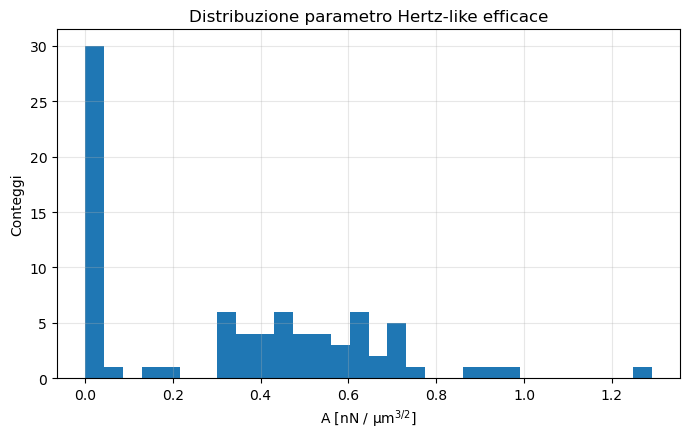

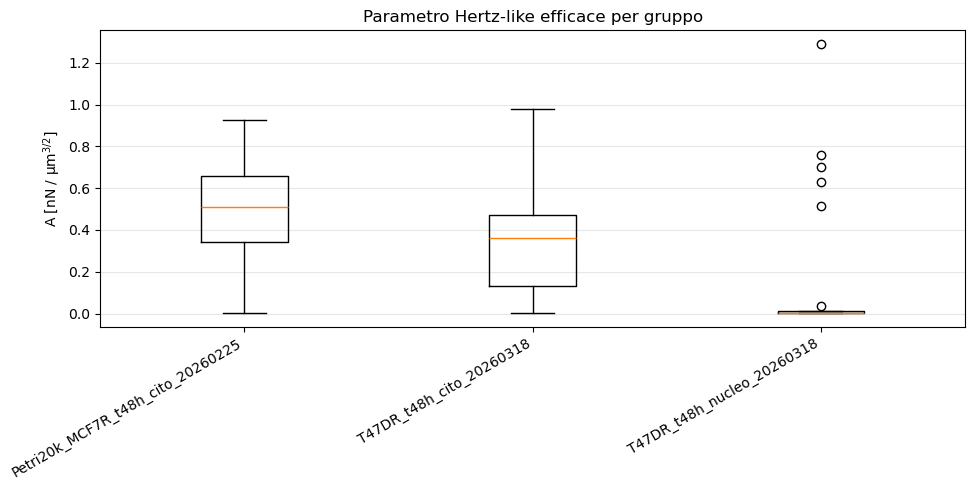

In [16]:

ok = fit_results[fit_results["fit_status"] == "ok"].copy()

print("Fit validi:", len(ok))
display(ok[["A_nN_per_um_3over2", "A_err_nN_per_um_3over2", "fit_r2", "fit_rmse_nN", "baseline_noise_pN"]].describe())

plt.figure(figsize=(7, 4.5))
plt.hist(ok["A_nN_per_um_3over2"].replace([np.inf, -np.inf], np.nan).dropna(), bins=30)
plt.xlabel(r"A [nN / µm$^{3/2}$]")
plt.ylabel("Conteggi")
plt.title("Distribuzione parametro Hertz-like efficace")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(FIT_OUTPUT_DIR / "hist_A_hertz_like.png", dpi=160, bbox_inches="tight")
plt.show()

groups = [g for g in ok["group"].dropna().unique()]
data = [ok.loc[ok["group"] == g, "A_nN_per_um_3over2"].dropna().values for g in groups]

plt.figure(figsize=(10, 5))
plt.boxplot(data, labels=groups, showfliers=True)
plt.xticks(rotation=30, ha="right")
plt.ylabel(r"A [nN / µm$^{3/2}$]")
plt.title("Parametro Hertz-like efficace per gruppo")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(FIT_OUTPUT_DIR / "boxplot_A_by_group.png", dpi=160, bbox_inches="tight")
plt.show()



## 8. Curve con fit sospetto

Guardiamo le curve con fit peggiore. Tipicamente sono quelle con \(R^2\) basso, RMSE alto o parametro \(A\) fuori scala.


In [17]:

bad_fit = ok.sort_values(["fit_r2", "fit_rmse_nN"], ascending=[True, False]).head(20)
display(bad_fit[["csv_file", "group", "A_nN_per_um_3over2", "fit_r2", "fit_rmse_nN", "baseline_noise_pN", "fit_plot"]])


,csv_file,group,A_nN_per_um_3over2,fit_r2,fit_rmse_nN,baseline_noise_pN,fit_plot
68,nucleo-0038_segment0.csv,T47DR_t48h_nucleo_20260318,1.290523,-3.103462,0.271888,62.886191,/Users/gmoretti/Work/AFM/Code_General/afm_outp...
58,nucleo-0000_segment0.csv,T47DR_t48h_nucleo_20260318,0.702367,-3.044729,0.243736,86.029777,/Users/gmoretti/Work/AFM/Code_General/afm_outp...
66,nucleo-0030_segment0.csv,T47DR_t48h_nucleo_20260318,0.756431,-2.905824,0.259323,75.644668,/Users/gmoretti/Work/AFM/Code_General/afm_outp...
54,cito-0077_segment0.csv,T47DR_t48h_cito_20260318,0.977903,-2.775446,0.258447,92.469469,/Users/gmoretti/Work/AFM/Code_General/afm_outp...
23,cito-0079_segment0.csv,Petri20k_MCF7R_t48h_cito_20260225,0.658366,-2.730519,0.242881,83.163108,/Users/gmoretti/Work/AFM/Code_General/afm_outp...
2,cito-0007_segment0.csv,Petri20k_MCF7R_t48h_cito_20260225,0.632332,-2.705805,0.237547,53.647887,/Users/gmoretti/Work/AFM/Code_General/afm_outp...
57,cito-0088_segment0.csv,T47DR_t48h_cito_20260318,0.462396,-2.552631,0.178782,68.521596,/Users/gmoretti/Work/AFM/Code_General/afm_outp...
20,cito-0074_segment0.csv,Petri20k_MCF7R_t48h_cito_20260225,0.865249,-2.328644,0.286940,100.203260,/Users/gmoretti/Work/AFM/Code_General/afm_outp...
22,cito-0078_segment0.csv,Petri20k_MCF7R_t48h_cito_20260225,0.714447,-2.304341,0.294856,60.849762,/Users/gmoretti/Work/AFM/Code_General/afm_outp...
43,cito-0042_segment0.csv,T47DR_t48h_cito_20260318,0.541471,-2.290302,0.222043,76.279916,/Users/gmoretti/Work/AFM/Code_General/afm_outp...



## 9. Interpretazione provvisoria

Cose da controllare nei plot salvati:

- il contact point stimato cade dove inizia davvero la crescita della forza?
- il fit usa una regione sensata?
- il segno della forza è corretto?
- ci sono curve in cui l'algoritmo fitta il tratto sbagliato?
- l'ordinamento di `z` è coerente con l'approach?

Questa versione serve per individuare i problemi. La prossima iterazione migliorerà il contact point e la scelta automatica del fit range.
